In [35]:
import pandas as pd
import numpy as np
from pathlib import Path

In [36]:
!python smaparsing.py


sp500 1950-01-03 2026-10-09 19315 // duplicates: 0 // NaN cells: 0 // longest gap (in days): 7.0
nasdaq_comp 1971-02-05 2026-10-09 14037 // duplicates: 0 // NaN cells: 0 // longest gap (in days): 7.0
nasdaq100 1985-10-01 2026-10-09 10336 // duplicates: 0 // NaN cells: 0 // longest gap (in days): 7.0
ftse100 1984-01-03 2026-10-09 10805 // duplicates: 0 // NaN cells: 0 // longest gap (in days): 5.0
nikkei 1965-01-05 2026-10-09 15183 // duplicates: 0 // NaN cells: 0 // longest gap (in days): 11.0
dax 1987-12-30 2026-10-09 9807 // duplicates: 0 // NaN cells: 0 // longest gap (in days): 6.0
cac40 1990-03-01 2026-10-09 9299 // duplicates: 0 // NaN cells: 0 // longest gap (in days): 6.0
hang_seng 1986-12-31 2026-10-09 9816 // duplicates: 0 // NaN cells: 0 // longest gap (in days): 7.0
shanghai 1997-07-02 2026-10-09 7089 // duplicates: 0 // NaN cells: 0 // longest gap (in days): 20.0


In [37]:
original_data_path = Path("/home/pedrosalgado22/Documents/Github Repositories/SMAstrategy/data/raw")

processed_data_path = Path("/home/pedrosalgado22/Documents/Github Repositories/SMAstrategy/data/processed")

In [38]:
PAYMENT = 250
INTEREST_RATE = 0.02
START_DATE = "1986-01-01"

DIV_YIELD = { 
    "sp500": 0.02, "nasdaq_comp": 0.01, "nasdaq100": 0.01, "ftse100": 0.04,
    "nikkei": 0.01, "dax": 0.0, "cac40": 0.03, "hang_seng": 0.03, "shanghai": 0.02,
}

STRATEGIES = {"DCA": None, "SMA50": "sma_50", "SMA100": "sma_100", "SMA200": "sma_200"}

In [39]:
import pandas as pd

def simulate(df, sma_col, dividend_yield, values=None):
    dates = df.index.tolist()
    closes = df["Close"].tolist()
    if sma_col is not None:
        smas = df[sma_col].tolist()

    valid = df[(df.index >= START_DATE) & df["sma_200"].notna()]  # first day with sma_200 available
    start = df.index.get_loc(valid.index[0])

    cash = 0
    units = 0
    units_bought = 0
    total_spent = 0
    total_invested = 0
    n_buys = 0
    next_payment = dates[start].replace(day=1)  # payments on the 1st of each month
    if next_payment < dates[start]:
        next_payment += pd.DateOffset(months=1)

    for i in range(start, len(df)):
        days = (dates[i] - dates[i - 1]).days
        cash *= (1 + INTEREST_RATE) ** (days / 365)
        units *= (1 + dividend_yield) ** (days / 365)

        while next_payment <= dates[i]:
            cash += PAYMENT
            total_invested += PAYMENT
            next_payment += pd.DateOffset(months=1)

        if sma_col is None:
            signal = True
        else:
            signal = closes[i - 1] <= smas[i - 1]

        if cash > 0 and signal:
            units += cash / closes[i]
            units_bought += cash / closes[i]
            total_spent += cash
            n_buys += 1
            cash = 0

        if values is not None:
            values.append(units * closes[i] + cash)

    final_value = units * closes[-1] + cash
    return {
        "start_date": dates[start].date(),
        "end_date": dates[-1].date(),
        "total_invested": total_invested,
        "final_value": final_value,
        "total_return_pct": (final_value / total_invested - 1) * 100,
        "units": units,
        "avg_price": total_spent / units_bought if units_bought > 0 else None,
        "leftover_cash": cash,
        "n_buys": n_buys,
    }

In [40]:
df = pd.read_csv(processed_data_path / "sp500_processed.csv", index_col=0, parse_dates=True)
rows = []
for strategy, sma_col in STRATEGIES.items():
    rows.append(simulate(df, sma_col, DIV_YIELD["sp500"]))
pd.DataFrame(rows, index=STRATEGIES.keys())

,start_date,end_date,total_invested,final_value,total_return_pct,units,avg_price,leftover_cash,n_buys
DCA,1986-01-02,2026-10-09,122250,2.087175e+06,1607.300484,267.191211,835.312961,0.000000,489
SMA50,1986-01-02,2026-10-09,122250,2.082845e+06,1603.758664,266.604901,835.791791,250.108531,320
SMA100,1986-01-02,2026-10-09,122250,2.068941e+06,1592.385639,264.664148,833.781105,1506.857668,245
SMA200,1986-01-02,2026-10-09,122250,2.058492e+06,1583.838390,263.326510,839.489717,1506.857668,176


In [41]:
results_path = processed_data_path.parent.parent / "results"
results_path.mkdir(exist_ok=True)

rows = []
for name in DIV_YIELD:
    df = pd.read_csv(processed_data_path / f"{name}_processed.csv", index_col=0, parse_dates=True)
    for strategy, sma_col in STRATEGIES.items():
        row = {"index": name, "strategy": strategy}
        row.update(simulate(df, sma_col, DIV_YIELD[name]))
        rows.append(row)

results = pd.DataFrame(rows)

results.to_csv(results_path / "results.csv", index=False)

display(
    results.style.format({
        "total_invested": "{:,.0f}",
        "final_value": "{:,.0f}",
        "total_return_pct": "{:,.2f}",
        "units": "{:,.2f}",
        "avg_price": "{:,.2f}",
        "leftover_cash": "{:,.2f}",
    }, na_rep="NaN")
)

,index,strategy,start_date,end_date,total_invested,final_value,total_return_pct,units,avg_price,leftover_cash,n_buys
0,sp500,DCA,1986-01-02,2026-10-09,"122,250","2,087,175","1,607.30",267.19,835.31,0.00,489
1,sp500,SMA50,1986-01-02,2026-10-09,"122,250","2,082,845","1,603.76",266.60,835.79,250.11,320
2,sp500,SMA100,1986-01-02,2026-10-09,"122,250","2,068,941","1,592.39",264.66,833.78,"1,506.86",245
3,sp500,SMA200,1986-01-02,2026-10-09,"122,250","2,058,492","1,583.84",263.33,839.49,"1,506.86",176
4,nasdaq_comp,DCA,1986-01-02,2026-10-09,"122,250","3,419,351","2,697.02",124.95,"1,338.75",0.00,489
5,nasdaq_comp,SMA50,1986-01-02,2026-10-09,"122,250","3,392,734","2,675.24",123.97,"1,347.59",250.11,312
6,nasdaq_comp,SMA100,1986-01-02,2026-10-09,"122,250","3,388,331","2,671.64",123.81,"1,351.40",250.11,242
7,nasdaq_comp,SMA200,1986-01-02,2026-10-09,"122,250","3,399,826","2,681.04",124.18,"1,338.79","1,506.86",180
8,nasdaq100,DCA,1986-07-16,2026-10-09,"120,750","6,647,500","5,405.18",215.25,778.10,0.00,483
9,nasdaq100,SMA50,1986-07-16,2026-10-09,"120,750","6,592,313","5,359.47",213.45,783.84,250.11,314


0	sp500	DCA	1986-01-02	2026-10-09	531750	9.136301e+06	1618.157192	1169.590225	830.866235	0.000000	2127
1	sp500	SMA50	1986-01-02	2026-10-09	531750	9.109816e+06	1613.176487	1166.103672	832.489615	750.447763	887
2	sp500	SMA100	1986-01-02	2026-10-09	531750	9.049612e+06	1601.854550	1157.656388	829.936712	6532.346903	722
3	sp500	SMA200	1986-01-02	2026-10-09	531750	9.014362e+06	1595.225495	1153.143833	834.571852	6532.346903	588
4	nasdaq_comp	DCA	1986-01-02	2026-10-09	531750	1.495871e+07	2713.108661	546.613039	1331.624952	0.000000	2127
5	nasdaq_comp	SMA50	1986-01-02	2026-10-09	531750	1.481775e+07	2686.601035	541.434940	1343.393084	750.447763	914
6	nasdaq_comp	SMA100	1986-01-02	2026-10-09	531750	1.480049e+07	2683.354940	540.804193	1347.034633	750.447763	770
7	nasdaq_comp	SMA200	1986-01-02	2026-10-09	531750	1.488097e+07	2698.490729	543.533938	1330.648005	6532.346903	645
8	nasdaq100	DCA	1986-07-16	2026-10-09	524750	2.898173e+07	5422.959236	938.431800	775.647841	0.000000	2099
9	nasdaq100	SMA50	1986-07-16	2026-10-09	524750	2.870537e+07	5370.295290	929.459124	782.808093	750.447763	920
10	nasdaq100	SMA100	1986-07-16	2026-10-09	524750	2.861276e+07	5352.646077	926.460264	785.696854	750.447763	752
11	nasdaq100	SMA200	1986-07-16	2026-10-09	524750	2.919660e+07	5463.907316	945.177962	766.586109	6532.346903	600
12	ftse100	DCA	1986-01-02	2026-10-08	531750	3.948012e+06	642.456495	378.104175	4263.431927	0.000000	2127
13	ftse100	SMA50	1986-01-02	2026-10-08	531750	3.950097e+06	642.848613	378.303866	4255.567408	0.000000	1064
14	ftse100	SMA100	1986-01-02	2026-10-08	531750	3.894729e+06	632.436140	373.001199	4295.431807	0.000000	911
15	ftse100	SMA200	1986-01-02	2026-10-08	531750	3.935961e+06	640.190072	376.949974	4273.302256	0.000000	795
16	nikkei	DCA	1986-01-06	2026-10-08	531750	2.729073e+06	413.224872	39.527663	16634.087850	0.000000	2125
17	nikkei	SMA50	1986-01-06	2026-10-08	531750	2.716819e+06	410.920428	39.346558	16712.021549	250.040694	1133
18	nikkei	SMA100	1986-01-06	2026-10-08	531750	2.723668e+06	412.208354	39.445751	16676.338981	250.040694	1025
19	nikkei	SMA200	1986-01-06	2026-10-08	531750	2.734407e+06	414.227978	39.355497	16223.877161	17220.739434	981
20	dax	DCA	1988-10-14	2026-10-08	495500	2.851115e+06	475.401659	114.932019	4311.244211	0.000000	1982
21	dax	SMA50	1988-10-14	2026-10-08	495500	2.836521e+06	472.456325	114.343711	4340.184942	0.000000	891
22	dax	SMA100	1988-10-14	2026-10-08	495500	2.841623e+06	473.485933	114.549367	4337.855948	0.000000	797
23	dax	SMA200	1988-10-14	2026-10-08	495500	2.780449e+06	461.140075	111.881060	4414.666862	5018.900810	651
24	cac40	DCA	1990-12-17	2026-10-08	467250	1.948667e+06	317.050235	252.101603	3685.657067	0.000000	1869
25	cac40	SMA50	1990-12-17	2026-10-08	467250	1.948470e+06	317.008011	252.076079	3683.065480	0.000000	943
26	cac40	SMA100	1990-12-17	2026-10-08	467250	1.946828e+06	316.656636	251.863677	3683.359957	0.000000	836
27	cac40	SMA200	1990-12-17	2026-10-08	467250	1.920790e+06	311.083918	248.495039	3725.986467	0.000000	750
28	hang_seng	DCA	1987-10-26	2026-10-08	508250	2.757580e+06	442.563713	115.933933	10333.953986	0.000000	2033
29	hang_seng	SMA50	1987-10-26	2026-10-08	508250	2.746652e+06	440.413512	115.474482	10369.302608	0.000000	1042
30	hang_seng	SMA100	1987-10-26	2026-10-08	508250	2.718311e+06	434.837445	114.282999	10445.168218	0.000000	978
31	hang_seng	SMA200	1987-10-26	2026-10-08	508250	2.686811e+06	428.639643	112.958665	10545.814920	0.000000	865
32	shanghai	DCA	1998-04-29	2026-10-09	371000	NaN	NaN	231.244547	2262.477119	0.000000	1440
33	shanghai	SMA50	1998-04-29	2026-10-09	371000	NaN	NaN	227.852188	2294.714034	0.000000	798
34	shanghai	SMA100	1998-04-29	2026-10-09	371000	NaN	NaN	221.115612	2363.016341	0.000000	765
35	shanghai	SMA200	1998-04-29	2026-10-09	371000	NaN	NaN	224.699303	2327.071485	0.000000	739


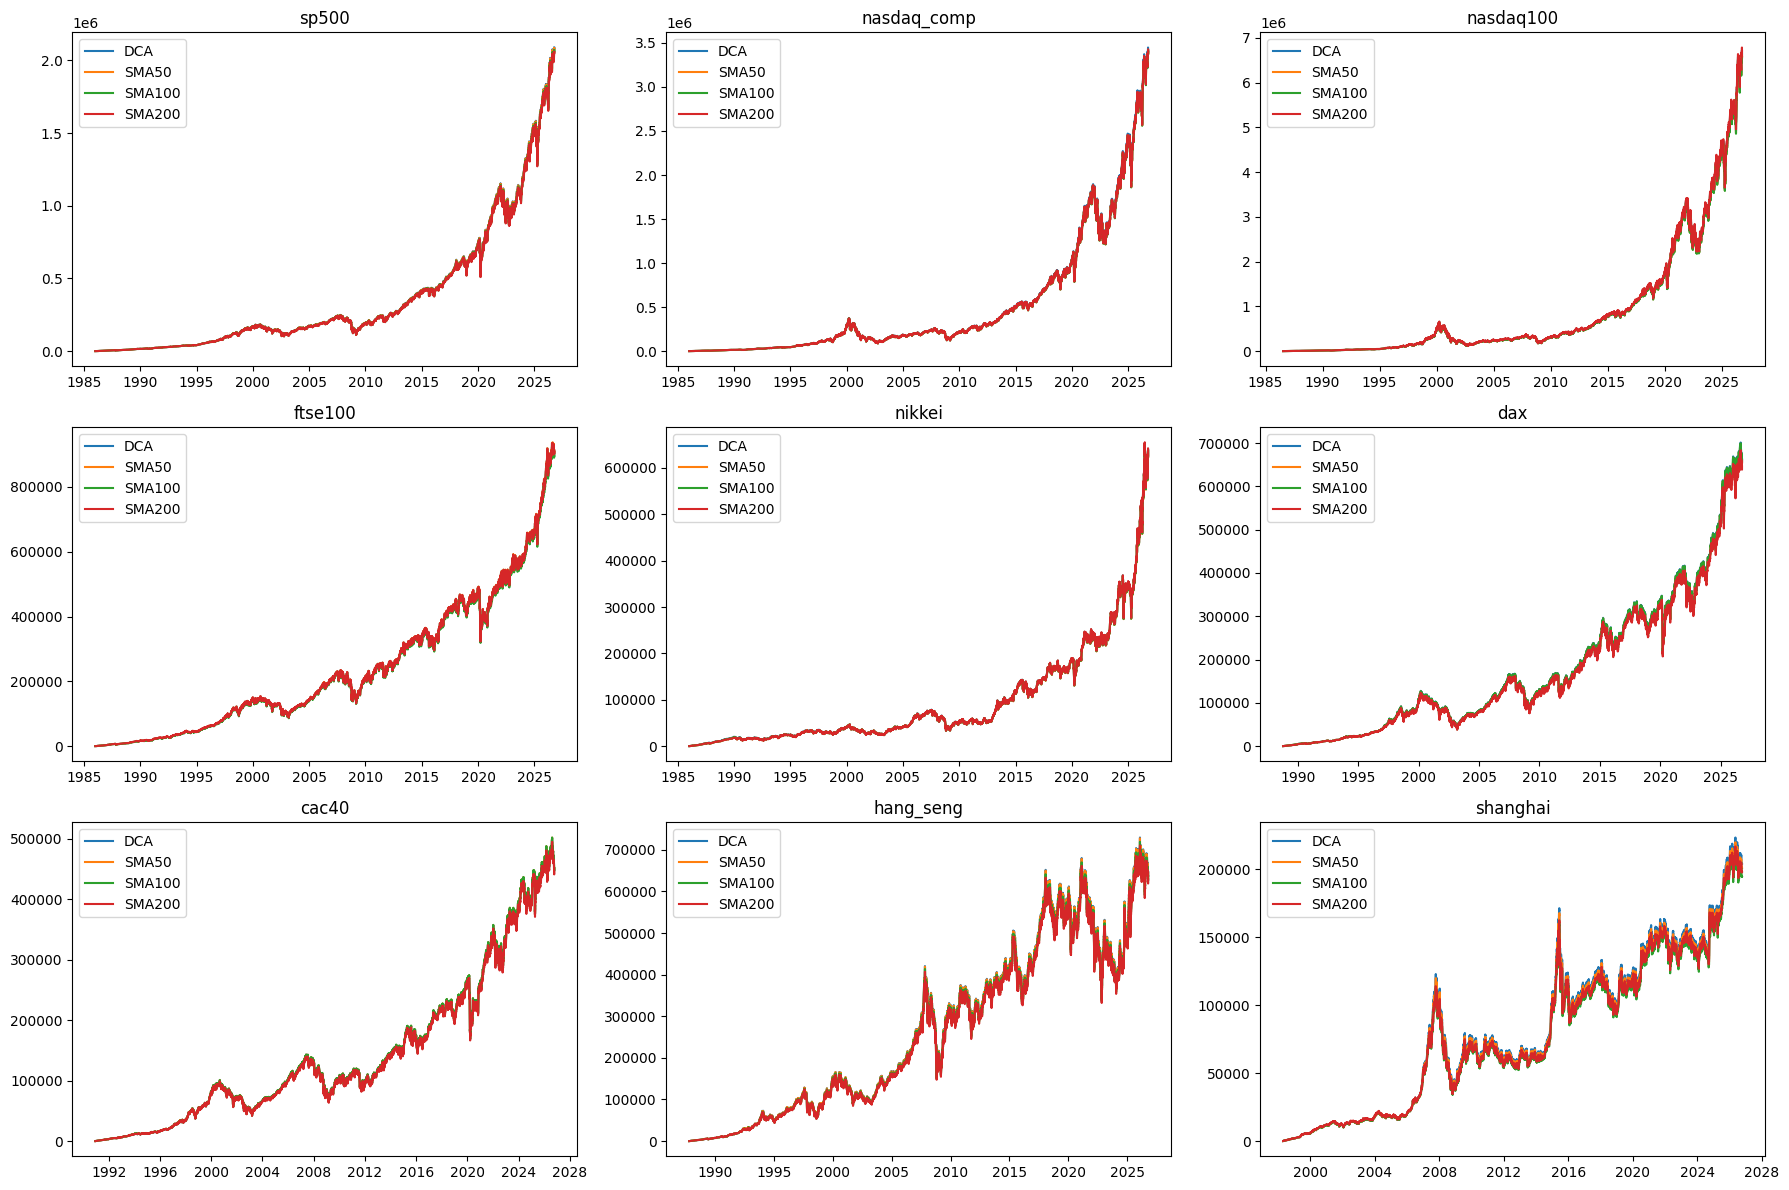

In [42]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 3, figsize=(18, 12))
for ax, name in zip(axes.flatten(), DIV_YIELD):
    df = pd.read_csv(processed_data_path / f"{name}_processed.csv", index_col=0, parse_dates=True).dropna(subset=["Close"])
    for strategy, sma_col in STRATEGIES.items():
        values = []
        simulate(df, sma_col, DIV_YIELD[name], values)
        ax.plot(df.index[-len(values):], values, label=strategy)
    ax.set_title(name)
    ax.legend()
plt.tight_layout()
plt.show()

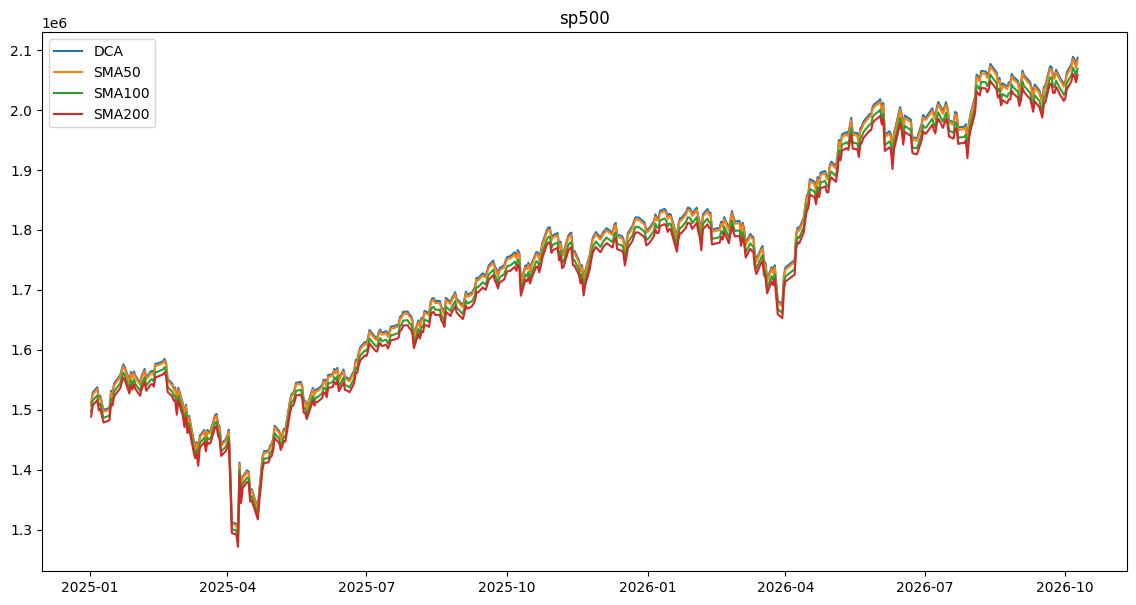

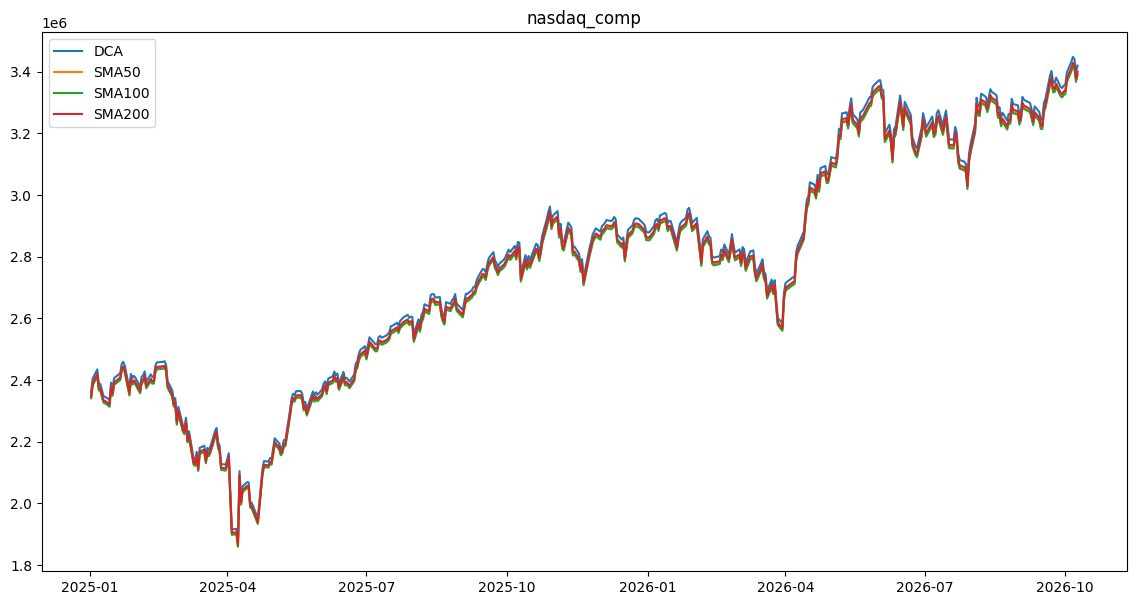

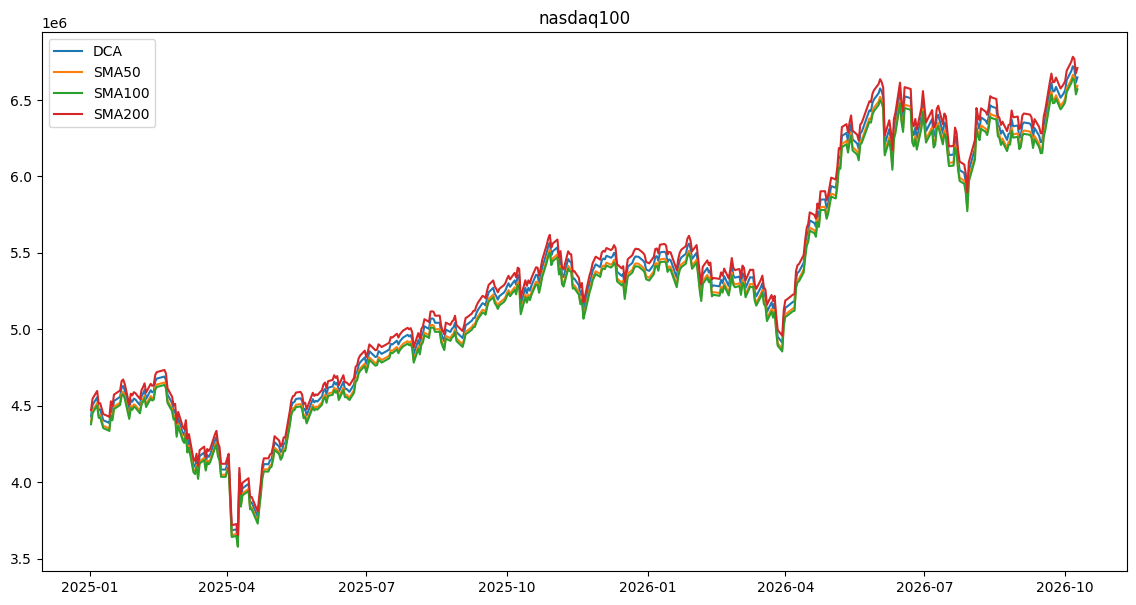

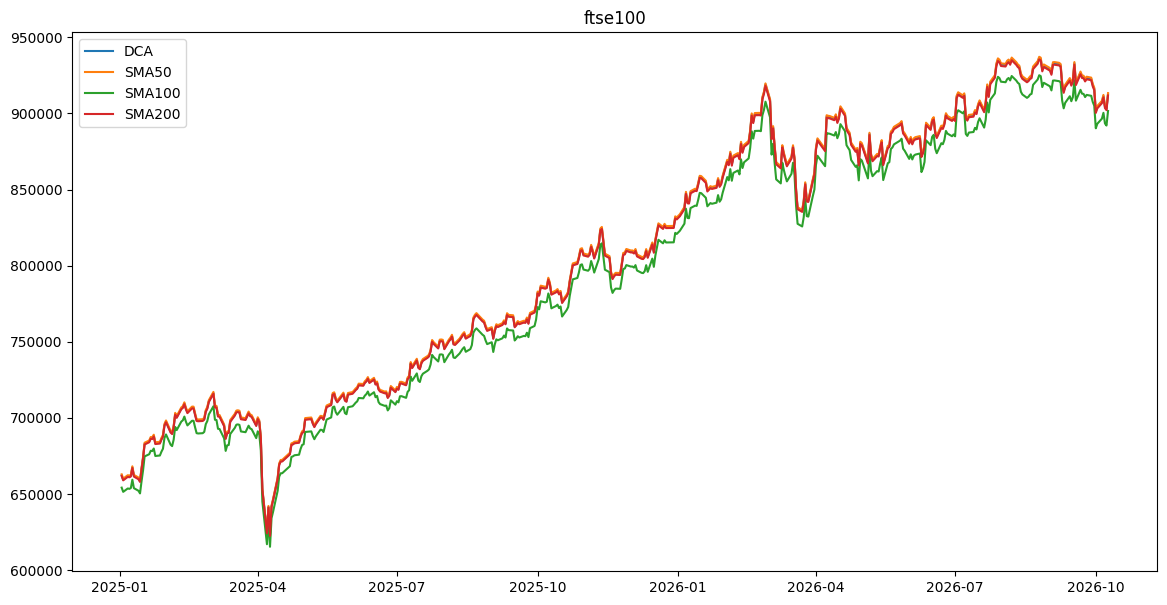

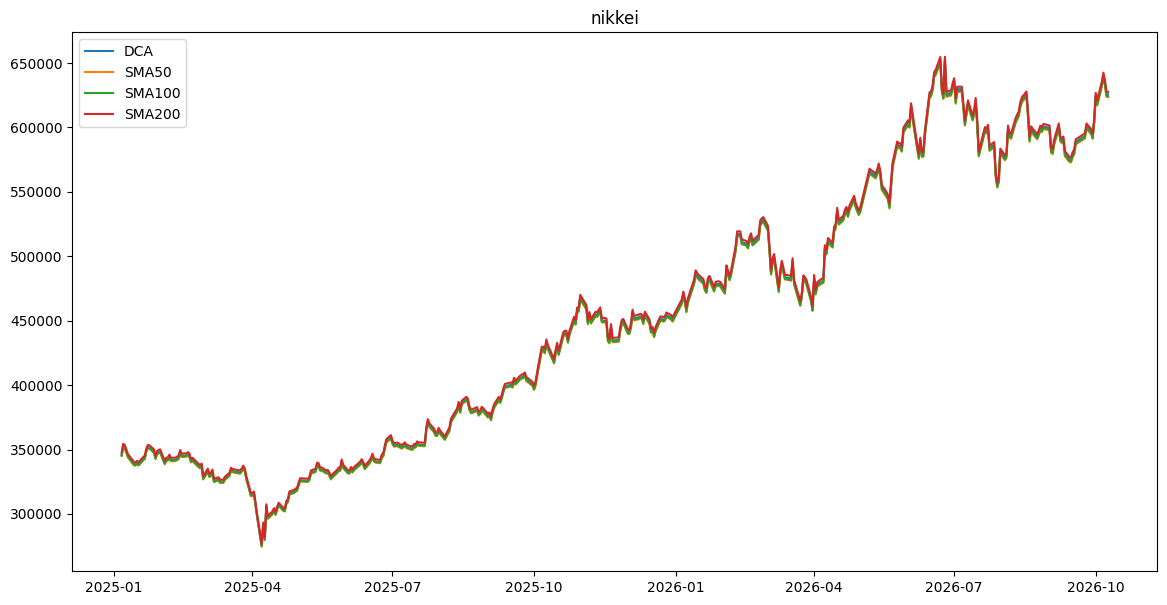

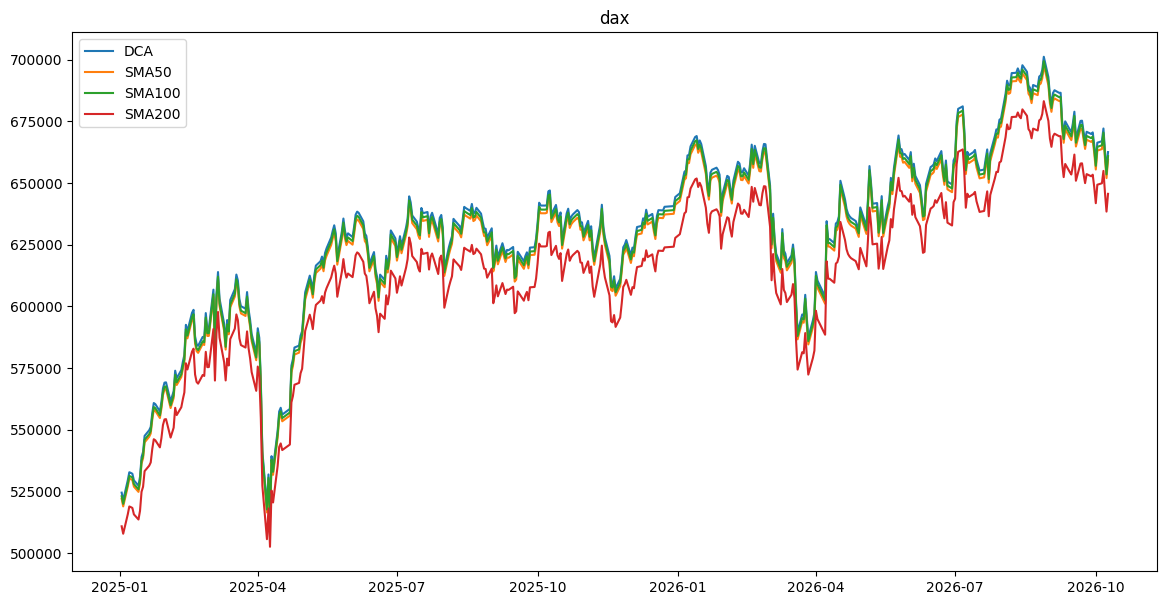

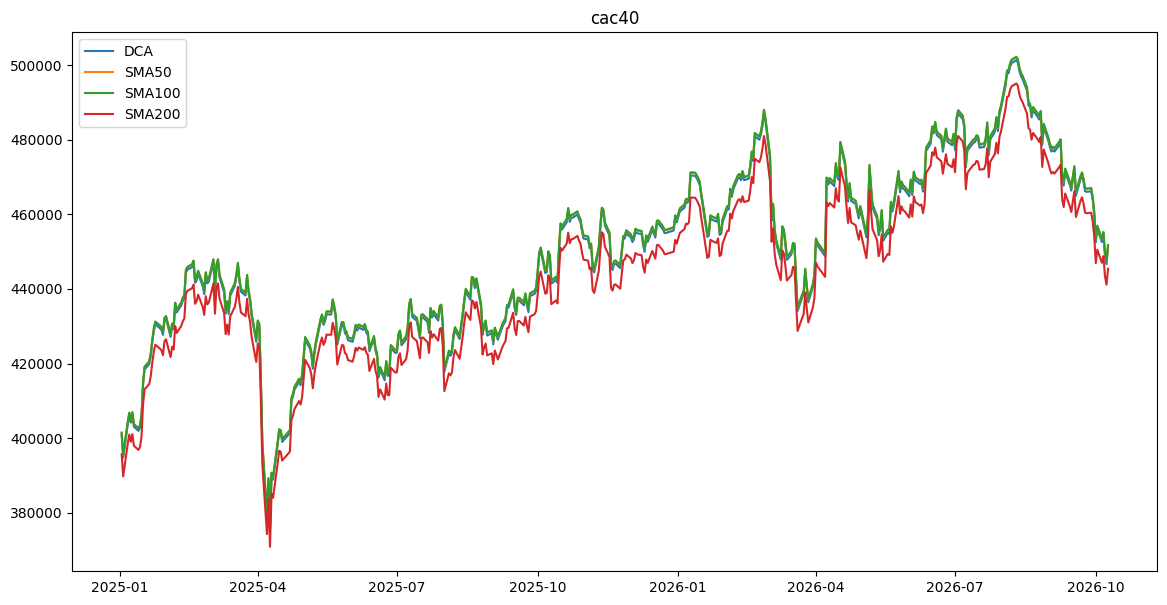

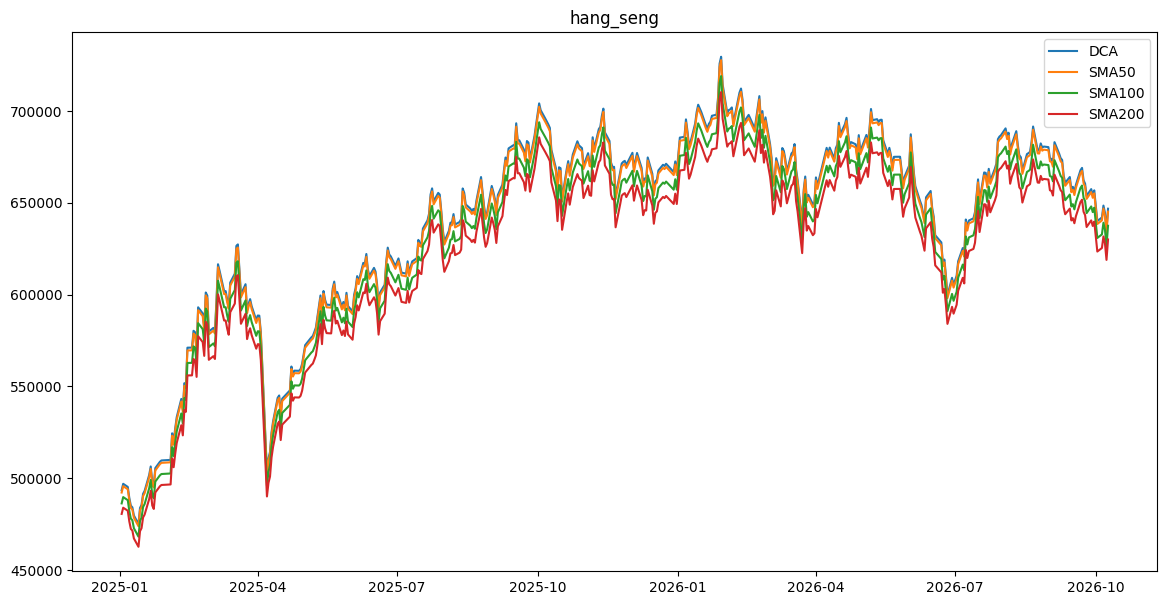

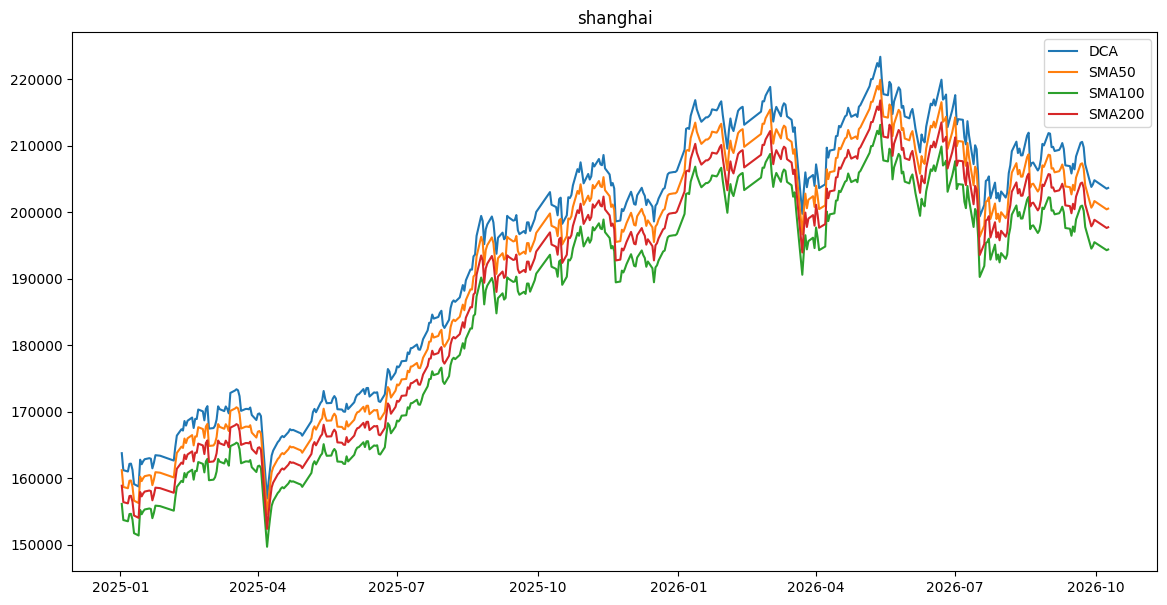

In [43]:
import matplotlib.pyplot as plt

for name in DIV_YIELD:
    df = pd.read_csv(processed_data_path / f"{name}_processed.csv", index_col=0, parse_dates=True).dropna(subset=["Close"])
    plt.figure(figsize=(14, 7))
    for strategy, sma_col in STRATEGIES.items():
        values = []
        simulate(df, sma_col, DIV_YIELD[name], values)
        series = pd.Series(values, index=df.index[-len(values):])["2025-01-01":]
        plt.plot(series.index, series.values, label=strategy)
    plt.title(name)
    plt.legend()
    plt.show()